In [2]:
# ============================================================
# CELL 1 — Libraries
# ============================================================

import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import Sequence
from tensorflow.keras.applications import EfficientNetB0

warnings.filterwarnings("ignore")
print("TensorFlow version:", tf.__version__)


2026-06-14 11:31:53.516699: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781436713.702972      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781436713.761945      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781436714.214277      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781436714.214313      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781436714.214315      58 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0


In [3]:
# ============================================================
# CELL 2 — Reproducibility + basic settings
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMAGE_SIZE = 200
IMG_SIZE = (IMAGE_SIZE, IMAGE_SIZE)
BATCH_SIZE = 32
EPOCHS = 10

OUTPUT_DIR = "/kaggle/working/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output directory:", OUTPUT_DIR)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


Output directory: /kaggle/working/outputs
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
# ============================================================
# CELL 3 — Input dataset path
# Works for both common Kaggle competition paths.
# ============================================================

candidate_paths = [
    "/kaggle/input/histopathologic-cancer-detection",
    "/kaggle/input/competitions/histopathologic-cancer-detection"
]

DATA_PATH = None
for path in candidate_paths:
    if os.path.exists(path):
        DATA_PATH = path
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Add the Kaggle competition dataset: histopathologic-cancer-detection"
    )

TRAIN_DIR = os.path.join(DATA_PATH, "train")
OFFICIAL_TEST_DIR = os.path.join(DATA_PATH, "test")
LABELS_PATH = os.path.join(DATA_PATH, "train_labels.csv")

print("DATA_PATH:", DATA_PATH)
print("Files:", os.listdir(DATA_PATH))
print("Train images:", len(os.listdir(TRAIN_DIR)))
print("Official test images:", len(os.listdir(OFFICIAL_TEST_DIR)) if os.path.exists(OFFICIAL_TEST_DIR) else 0)


DATA_PATH: /kaggle/input/competitions/histopathologic-cancer-detection
Files: ['sample_submission.csv', 'train_labels.csv', 'test', 'train']
Train images: 220025
Official test images: 57458


In [5]:
# ============================================================
# CELL 4 — Load labels and create file paths
# ============================================================

df = pd.read_csv(LABELS_PATH)
df["filepath"] = df["id"].apply(lambda x: os.path.join(TRAIN_DIR, x + ".tif"))
df["label"] = df["label"].astype(int)

print(df.head())
print("\nClass distribution:")
print(df["label"].value_counts())
print("\nMissing files:", (~df["filepath"].apply(os.path.exists)).sum())


                                         id  label  \
0  f38a6374c348f90b587e046aac6079959adf3835      0   
1  c18f2d887b7ae4f6742ee445113fa1aef383ed77      1   
2  755db6279dae599ebb4d39a9123cce439965282d      0   
3  bc3f0c64fb968ff4a8bd33af6971ecae77c75e08      0   
4  068aba587a4950175d04c680d38943fd488d6a9d      0   

                                            filepath  
0  /kaggle/input/competitions/histopathologic-can...  
1  /kaggle/input/competitions/histopathologic-can...  
2  /kaggle/input/competitions/histopathologic-can...  
3  /kaggle/input/competitions/histopathologic-can...  
4  /kaggle/input/competitions/histopathologic-can...  

Class distribution:
label
0    130908
1     89117
Name: count, dtype: int64

Missing files: 0


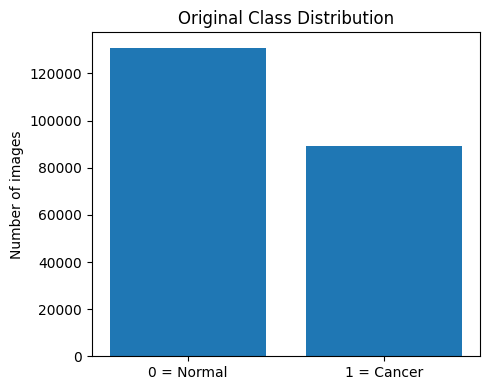

In [6]:
# ============================================================
# CELL 5 — Save class distribution plot
# ============================================================

class_counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(["0 = Normal", "1 = Cancer"], class_counts.values)
plt.title("Original Class Distribution")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "class_distribution_original.png"), dpi=300, bbox_inches="tight")
plt.show()


In [7]:
# ============================================================
# CELL 6 — Stratified split: train / validation / test
# Official Kaggle test has no labels, so evaluation uses this held-out test split.
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"\n{name} shape:", part.shape)
    print(part["label"].value_counts(normalize=False).sort_index())

split_counts = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "count": [len(train_df), len(val_df), len(test_df)]
})
split_counts.to_csv(os.path.join(OUTPUT_DIR, "split_counts.csv"), index=False)



Train shape: (154017, 3)
label
0    91635
1    62382
Name: count, dtype: int64

Validation shape: (33004, 3)
label
0    19636
1    13368
Name: count, dtype: int64

Test shape: (33004, 3)
label
0    19637
1    13367
Name: count, dtype: int64


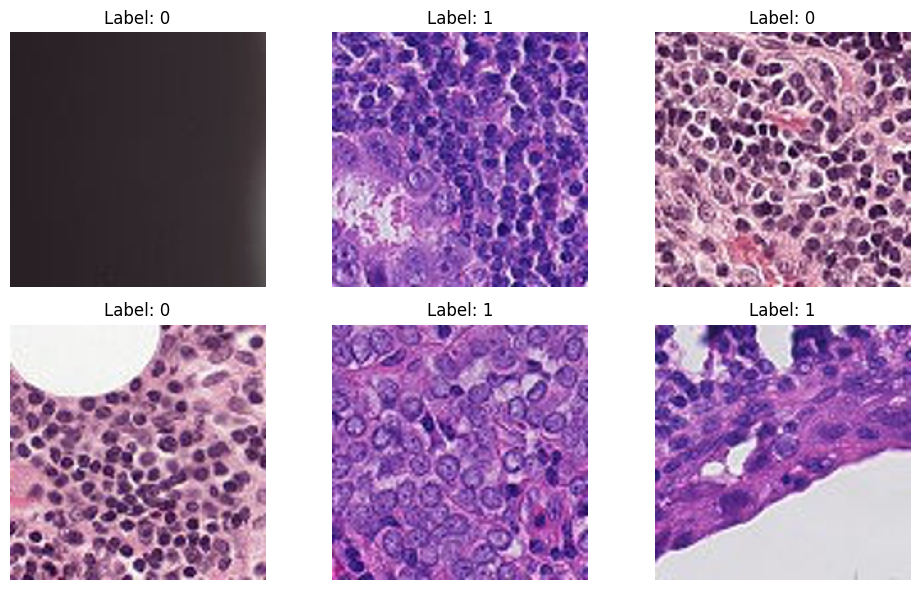

In [8]:
# ============================================================
# CELL 7 — Image loading and preprocessing helpers
# Images are kept in 0–255 range because Keras EfficientNet includes preprocessing internally.
# ============================================================

def load_image(path, image_size=IMG_SIZE):
    image = Image.open(path).convert("RGB")
    image = image.resize(image_size)
    image = np.asarray(image, dtype=np.float32)
    return image


def show_samples(dataframe, n=6, filename="sample_images.png"):
    sample_df = dataframe.sample(n, random_state=SEED).reset_index(drop=True)
    plt.figure(figsize=(10, 6))

    for i in range(n):
        img = load_image(sample_df.loc[i, "filepath"])
        label = sample_df.loc[i, "label"]

        plt.subplot(2, 3, i + 1)
        plt.imshow(img.astype(np.uint8))
        plt.title(f"Label: {label}")
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()

show_samples(df, n=6)


In [9]:
# ============================================================
# CELL 8 — Manual batch-level SMOTE for image batches
# Why batch-level? Full SMOTE on all 200x200x3 images is too memory-heavy on Kaggle.
# This generates synthetic minority images inside each training batch.
# ============================================================

def batch_smote_images(X, y, target_batch_size=BATCH_SIZE, seed=SEED):
    rng = np.random.default_rng(seed)

    X = X.astype(np.float32)
    y = y.astype(np.int32)

    classes, counts = np.unique(y, return_counts=True)

    # If the batch has only one class, duplicate samples to keep training stable.
    if len(classes) < 2:
        idx = rng.choice(len(y), size=target_batch_size, replace=True)
        return X[idx], y[idx]

    majority_class = classes[np.argmax(counts)]
    minority_class = classes[np.argmin(counts)]
    majority_count = counts.max()
    minority_count = counts.min()

    X_min = X[y == minority_class]
    n_needed = majority_count - minority_count

    synthetic_images = []

    if n_needed > 0:
        if len(X_min) >= 2:
            for _ in range(n_needed):
                i, j = rng.choice(len(X_min), size=2, replace=False)
                lam = rng.random()
                synthetic = X_min[i] + lam * (X_min[j] - X_min[i])
                synthetic_images.append(synthetic)
        else:
            for _ in range(n_needed):
                synthetic_images.append(X_min[0].copy())

    if synthetic_images:
        X_syn = np.stack(synthetic_images).astype(np.float32)
        y_syn = np.full(len(X_syn), minority_class, dtype=np.int32)
        X_bal = np.concatenate([X, X_syn], axis=0)
        y_bal = np.concatenate([y, y_syn], axis=0)
    else:
        X_bal, y_bal = X, y

    # Return exactly target_batch_size samples.
    replace = len(y_bal) < target_batch_size
    idx = rng.choice(len(y_bal), size=target_batch_size, replace=replace)
    X_bal = X_bal[idx]
    y_bal = y_bal[idx]

    # Keep valid image pixel range.
    X_bal = np.clip(X_bal, 0, 255).astype(np.float32)
    return X_bal, y_bal.astype(np.float32)


In [10]:
# ============================================================
# CELL 9 — Generators / Sequences
# Train generator uses batch-level SMOTE.
# Validation and test generators do NOT use SMOTE.
# ============================================================

class HistopathSequence(Sequence):
    def __init__(self, dataframe, batch_size=BATCH_SIZE, image_size=IMG_SIZE,
                 shuffle=False, use_smote=False, seed=SEED):
        self.dataframe = dataframe.reset_index(drop=True)
        self.batch_size = batch_size
        self.image_size = image_size
        self.shuffle = shuffle
        self.use_smote = use_smote
        self.seed = seed
        self.indexes = np.arange(len(self.dataframe))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        batch_indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        batch_df = self.dataframe.iloc[batch_indexes]

        X = np.stack([load_image(path, self.image_size) for path in batch_df["filepath"].values])
        y = batch_df["label"].values.astype(np.float32)

        if self.use_smote:
            X, y = batch_smote_images(
                X,
                y,
                target_batch_size=self.batch_size,
                seed=self.seed + index
            )

        return X, y

    def on_epoch_end(self):
        if self.shuffle:
            rng = np.random.default_rng(self.seed)
            rng.shuffle(self.indexes)


train_gen = HistopathSequence(train_df, batch_size=BATCH_SIZE, shuffle=True, use_smote=True)
val_gen = HistopathSequence(val_df, batch_size=BATCH_SIZE, shuffle=False, use_smote=False)
test_gen = HistopathSequence(test_df, batch_size=BATCH_SIZE, shuffle=False, use_smote=False)

X_batch, y_batch = train_gen[0]
print("Batch X shape:", X_batch.shape)
print("Batch y shape:", y_batch.shape)
print("Batch labels:", np.unique(y_batch, return_counts=True))


Batch X shape: (32, 200, 200, 3)
Batch y shape: (32,)
Batch labels: (array([0., 1.], dtype=float32), array([18, 14]))


In [11]:
# ============================================================
# CELL 10 — Better model: EfficientNetB0 transfer learning
# Single-stage training: no separate freeze/unfreeze loop.
# ============================================================

def build_model(image_size=IMAGE_SIZE):
    inputs = layers.Input(shape=(image_size, image_size, 3), name="image_input")

    data_augmentation = models.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.10),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
    ], name="data_augmentation")

    x = data_augmentation(inputs)

    try:
        base_model = EfficientNetB0(
            include_top=False,
            weights="imagenet",
            input_shape=(image_size, image_size, 3),
            name="efficientnetb0"
        )
        print("Loaded EfficientNetB0 with ImageNet weights.")
    except Exception as e:
        print("Could not load ImageNet weights. Using weights=None.")
        print("Reason:", e)
        base_model = EfficientNetB0(
            include_top=False,
            weights=None,
            input_shape=(image_size, image_size, 3),
            name="efficientnetb0"
        )

    # Single-stage fine-tuning: train only the last part of EfficientNet.
    base_model.trainable = True
    for layer in base_model.layers[:-40]:
        layer.trainable = False

    # Keep BatchNorm stable during fine-tuning.
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    features = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(features)
    x = layers.Dropout(0.35, name="top_dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)

    model = models.Model(inputs, outputs, name="EfficientNetB0_Histopathology")
    return model, base_model

model, base_model = build_model()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()


I0000 00:00:1781437329.466806      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781437329.472583      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Loaded EfficientNetB0 with ImageNet weights.


Model: "EfficientNetB0_Histopathology"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ top_dropout (Dropout)           │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 2,038,801 (7.78 MB)

 Non-trainable params: 2,012,051 (7.68 MB)

In [12]:
# ============================================================
# CELL 11 — Single-stage training loop
# ============================================================

checkpoint_path = os.path.join(OUTPUT_DIR, "best_efficientnet_smote_model.keras")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

history_df = pd.DataFrame(history.history)
history_df.to_csv(os.path.join(OUTPUT_DIR, "training_history.csv"), index=False)
print(history_df.tail())


Epoch 1/10


E0000 00:00:1781437343.590120      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_Histopathology_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1781437346.651625     136 cuda_dnn.cc:529] Loaded cuDNN version 91002


4814/4814 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - accuracy: 0.8701 - auc: 0.9417 - loss: 0.3009 - precision: 0.8805 - recall: 0.8565
Epoch 1: val_auc improved from None to 0.97370, saving model to /kaggle/working/outputs/best_efficientnet_smote_model.keras

Epoch 1: finished saving model to /kaggle/working/outputs/best_efficientnet_smote_model.keras
4814/4814 ━━━━━━━━━━━━━━━━━━━━ 1337s 274ms/step - accuracy: 0.8929 - auc: 0.9582 - loss: 0.2597 - precision: 0.9046 - recall: 0.8783 - val_accuracy: 0.9214 - val_auc: 0.9737 - val_loss: 0.1996 - val_precision: 0.9134 - val_recall: 0.8903 - learning_rate: 1.0000e-04
Epoch 2/10
4814/4814 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9162 - auc: 0.9721 - loss: 0.2114 - precision: 0.9276 - recall: 0.9030
Epoch 2: val_auc improved from 0.97370 to 0.97909, saving model to /kaggle/working/outputs/best_efficientnet_smote_model.keras

Epoch 2: finished saving model to /kaggle/working/outputs/best_efficientnet_smote_model.keras
4814/4814 ━━━━━━━━━━━━

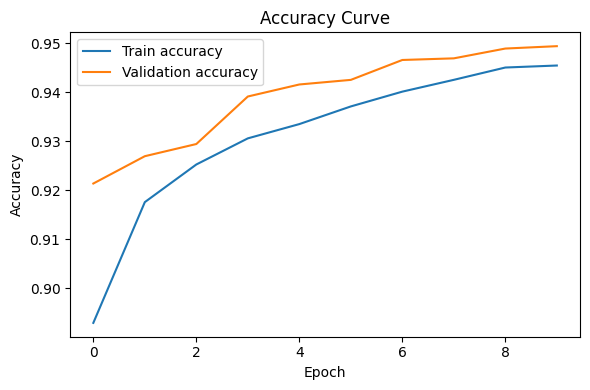

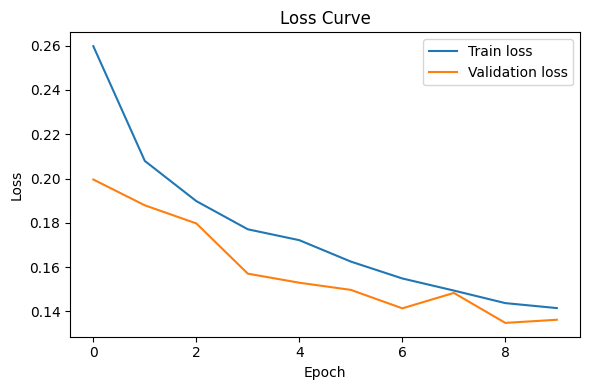

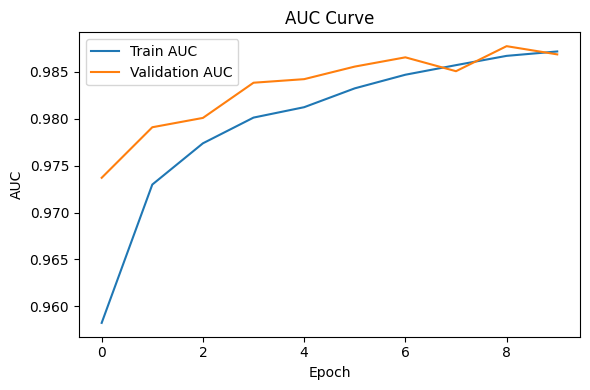

In [13]:
def plot_history(history_df):
    plt.figure(figsize=(6, 4))
    plt.plot(history_df["accuracy"], label="Train accuracy")
    plt.plot(history_df["val_accuracy"], label="Validation accuracy")
    plt.title("Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # Loss
    plt.figure(figsize=(6, 4))
    plt.plot(history_df["loss"], label="Train loss")
    plt.plot(history_df["val_loss"], label="Validation loss")
    plt.title("Loss Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve.png"), dpi=300, bbox_inches="tight")
    plt.show()

    # AUC
    plt.figure(figsize=(6, 4))
    plt.plot(history_df["auc"], label="Train AUC")
    plt.plot(history_df["val_auc"], label="Validation AUC")
    plt.title("AUC Curve")
    plt.xlabel("Epoch")
    plt.ylabel("AUC")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "auc_curve.png"), dpi=300, bbox_inches="tight")
    plt.show()

plot_history(history_df)


In [14]:
# ============================================================
# CELL 13 — Testing evaluation on held-out labeled test split
# ============================================================

if os.path.exists(checkpoint_path):
    model = tf.keras.models.load_model(checkpoint_path)
    print("Loaded best saved model:", checkpoint_path)

results = model.evaluate(test_gen, verbose=1, return_dict=True)
print("\nTest results:")
print(results)

y_true = test_df.reset_index(drop=True)["label"].values.astype(int)
y_prob = model.predict(test_gen, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
report = classification_report(y_true, y_pred, target_names=["Normal", "Cancer"], digits=4)
roc_auc = roc_auc_score(y_true, y_prob)
pr_auc = average_precision_score(y_true, y_prob)

print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(report)
print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

metrics_summary = {
    **{k: float(v) for k, v in results.items()},
    "roc_auc": float(roc_auc),
    "pr_auc": float(pr_auc)
}

with open(os.path.join(OUTPUT_DIR, "metrics_summary.json"), "w") as f:
    json.dump(metrics_summary, f, indent=4)

with open(os.path.join(OUTPUT_DIR, "classification_report.txt"), "w") as f:
    f.write(report)


Loaded best saved model: /kaggle/working/outputs/best_efficientnet_smote_model.keras
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 279s 266ms/step - accuracy: 0.9487 - auc: 0.9880 - loss: 0.1341 - precision: 0.9627 - recall: 0.9086

Test results:
{'accuracy': 0.9487335085868835, 'auc': 0.9880424737930298, 'loss': 0.13412058353424072, 'precision': 0.9627427458763123, 'recall': 0.9085808396339417}
1032/1032 ━━━━━━━━━━━━━━━━━━━━ 83s 78ms/step

Confusion Matrix:
[[19167   470]
 [ 1222 12145]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9401    0.9761    0.9577     19637
      Cancer     0.9627    0.9086    0.9349     13367

    accuracy                         0.9487     33004
   macro avg     0.9514    0.9423    0.9463     33004
weighted avg     0.9493    0.9487    0.9485     33004

ROC-AUC: 0.9883743292292476
PR-AUC: 0.9849477721620641


In [27]:
import os
import shutil
from IPython.display import FileLink, display, HTML

model_path = "/kaggle/working/outputs/best_efficientnet_smote_model.keras"

# Put downloadable zip in Kaggle working root
download_zip = "/kaggle/working/best_model.zip"

print("Checking model...")
print("Exists:", os.path.exists(model_path))

if not os.path.exists(model_path):
    print("❌ Model not found.")
    print("Files in /kaggle/working:")
    print(os.listdir("/kaggle/working"))

    if os.path.exists("/kaggle/working/outputs"):
        print("\nFiles in /kaggle/working/outputs:")
        print(os.listdir("/kaggle/working/outputs"))

else:
    print("✅ Model found")
    print("Size MB:", os.path.getsize(model_path) / (1024 * 1024))

    # Remove old zip if exists
    if os.path.exists(download_zip):
        os.remove(download_zip)

    # Create zip
    shutil.make_archive(
        base_name="/kaggle/working/best_model",
        format="zip",
        root_dir="/kaggle/working/outputs",
        base_dir="best_efficientnet_smote_model.keras"
    )

    print("✅ ZIP created:", download_zip)
    print("ZIP Size MB:", os.path.getsize(download_zip) / (1024 * 1024))

    # IMPORTANT: use relative link, not absolute path
    os.chdir("/kaggle/working")

    display(FileLink("best_model.zip"))
    display(HTML('<a href="best_model.zip" download>⬇️ Click here to download best_model.zip</a>'))

Checking model...
Exists: True
✅ Model found
Size MB: 31.841745376586914
✅ ZIP created: /kaggle/working/best_model.zip
ZIP Size MB: 28.908370971679688


/kaggle/working/best_model.zip

<Figure size 500x400 with 0 Axes>

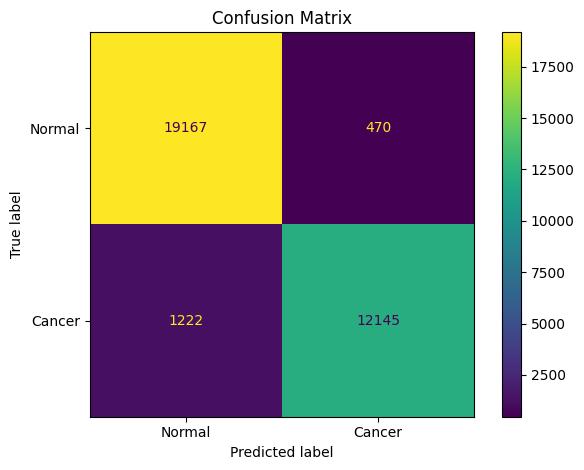

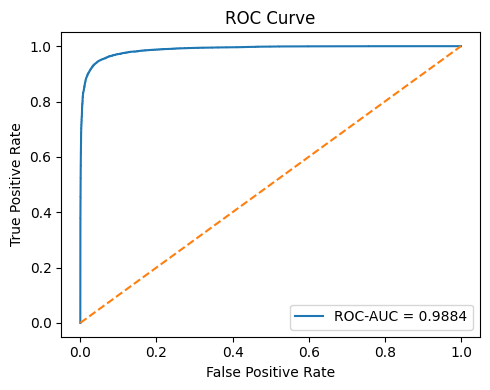

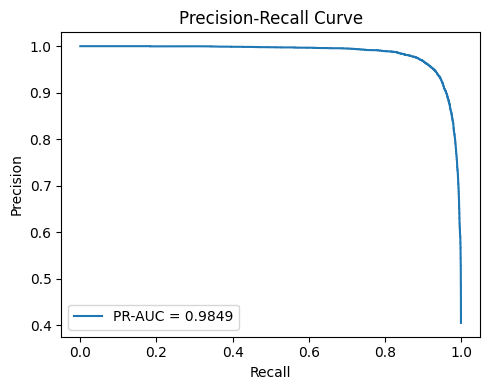

In [15]:
# ============================================================
# CELL 14 — Save evaluation plots: confusion matrix, ROC, PR curve
# ============================================================

# Confusion matrix
plt.figure(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Cancer"])
disp.plot(values_format="d")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=300, bbox_inches="tight")
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_curve.png"), dpi=300, bbox_inches="tight")
plt.show()

# Precision-Recall curve
precision, recall, _ = precision_recall_curve(y_true, y_prob)
plt.figure(figsize=(5, 4))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "precision_recall_curve.png"), dpi=300, bbox_inches="tight")
plt.show()


In [21]:
# ============================================================
# CELL 15 — XAI 1: Grad-CAM
# ============================================================

def get_last_conv_layer_name(base_model):
    for layer in reversed(base_model.layers):
        if isinstance(layer, layers.Conv2D):
            return layer.name
    raise ValueError("No Conv2D layer found in base model.")

last_conv_name = get_last_conv_layer_name(base_model)
print("Last convolution layer:", last_conv_name)

# Build a model that returns EfficientNet last conv output and EfficientNet final feature map.
last_conv_layer = base_model.get_layer(last_conv_name)
grad_base_model = tf.keras.models.Model(
    inputs=base_model.input,
    outputs=[last_conv_layer.output, base_model.output]
)


def classifier_head(base_output, training=False):
    x = model.get_layer("gap")(base_output)
    x = model.get_layer("top_dropout")(x, training=training)
    return model.get_layer("prediction")(x)


def make_gradcam_heatmap(img_array):
    # img_array shape: (1, 200, 200, 3)
    img_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)

    with tf.GradientTape() as tape:
        conv_outputs, base_outputs = grad_base_model(img_tensor, training=False)
        tape.watch(conv_outputs)
        preds = classifier_head(base_outputs, training=False)
        loss = preds[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), float(preds.numpy()[0][0])


def overlay_heatmap(image, heatmap, alpha=0.45):
    heatmap = Image.fromarray(np.uint8(255 * heatmap)).resize((IMAGE_SIZE, IMAGE_SIZE))
    heatmap = np.asarray(heatmap)
    colored_heatmap = plt.cm.jet(heatmap / 255.0)[..., :3] * 255
    overlay = colored_heatmap * alpha + image * (1 - alpha)
    return np.clip(overlay, 0, 255).astype(np.uint8)


Last convolution layer: top_conv


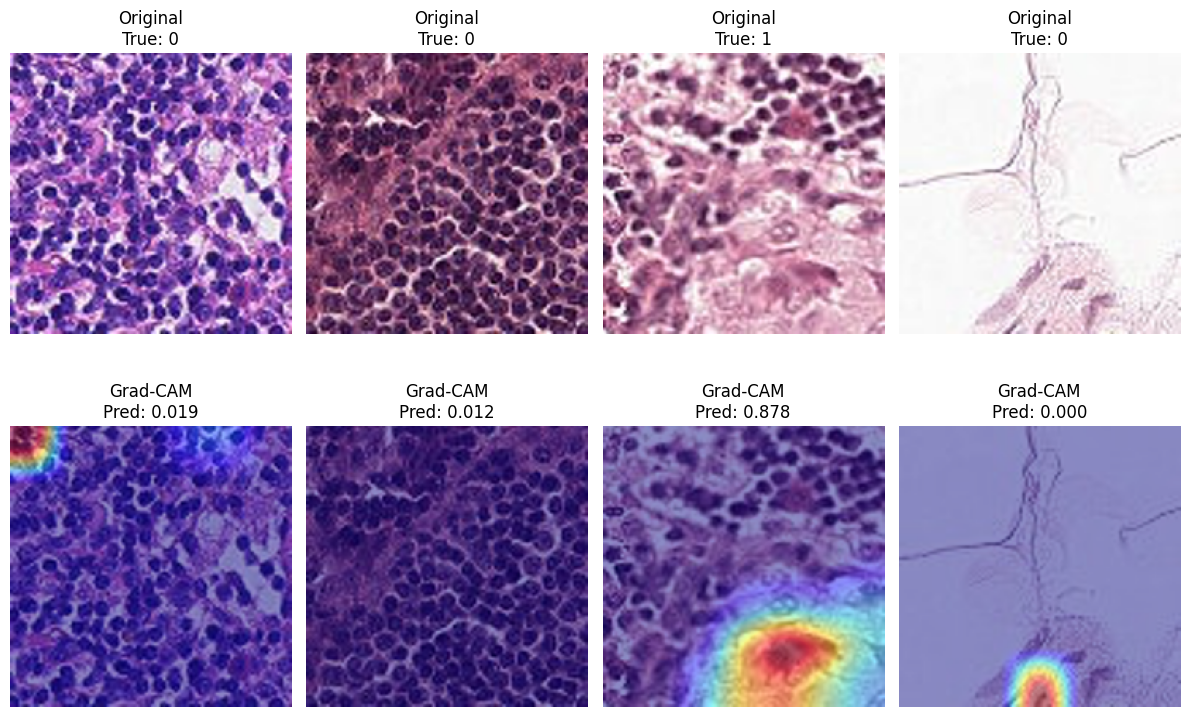

In [22]:
# ============================================================
# CELL 16 — Save Grad-CAM examples
# ============================================================

sample_xai_df = test_df.sample(4, random_state=SEED).reset_index(drop=True)

plt.figure(figsize=(12, 8))

for i in range(len(sample_xai_df)):
    img = load_image(sample_xai_df.loc[i, "filepath"])
    img_batch = np.expand_dims(img, axis=0)
    heatmap, pred_prob = make_gradcam_heatmap(img_batch)
    overlay = overlay_heatmap(img, heatmap)
    true_label = sample_xai_df.loc[i, "label"]

    plt.subplot(2, 4, i + 1)
    plt.imshow(img.astype(np.uint8))
    plt.title(f"Original\nTrue: {true_label}")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(overlay)
    plt.title(f"Grad-CAM\nPred: {pred_prob:.3f}")
    plt.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "gradcam_examples.png"), dpi=300, bbox_inches="tight")
plt.show()


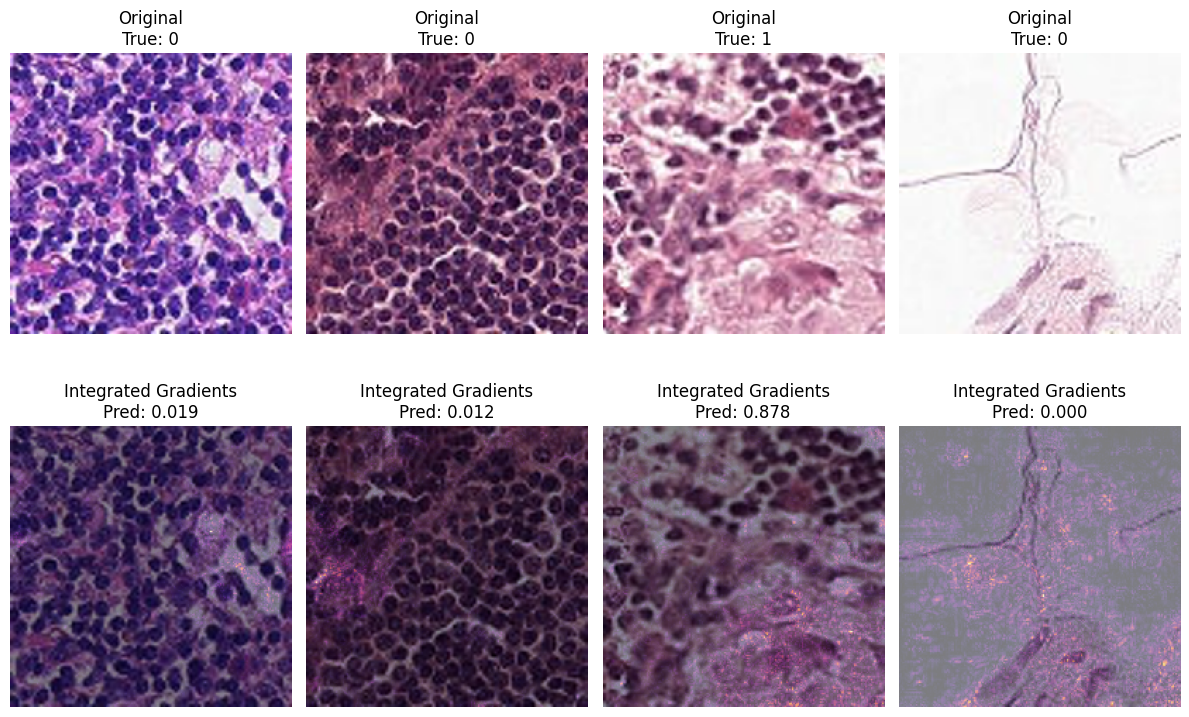

In [23]:
# ============================================================
# CELL 17 — XAI 2: Integrated Gradients
# ============================================================

def integrated_gradients(model, image, baseline=None, steps=32):
    # image shape: (1, H, W, 3), float32 0–255
    image = tf.convert_to_tensor(image, dtype=tf.float32)

    if baseline is None:
        baseline = tf.zeros_like(image)
    else:
        baseline = tf.convert_to_tensor(baseline, dtype=tf.float32)

    alphas = tf.linspace(0.0, 1.0, steps + 1)
    interpolated_images = baseline + alphas[:, None, None, None] * (image - baseline)

    with tf.GradientTape() as tape:
        tape.watch(interpolated_images)
        preds = model(interpolated_images, training=False)[:, 0]

    grads = tape.gradient(preds, interpolated_images)
    avg_grads = tf.reduce_mean(grads[:-1], axis=0)
    integrated_grads = (image[0] - baseline[0]) * avg_grads

    attribution = tf.reduce_sum(tf.abs(integrated_grads), axis=-1).numpy()
    attribution = attribution / (attribution.max() + 1e-8)
    return attribution


plt.figure(figsize=(12, 8))

for i in range(len(sample_xai_df)):
    img = load_image(sample_xai_df.loc[i, "filepath"])
    img_batch = np.expand_dims(img, axis=0)
    attr = integrated_gradients(model, img_batch, steps=32)
    pred_prob = float(model.predict(img_batch, verbose=0).ravel()[0])
    true_label = sample_xai_df.loc[i, "label"]

    plt.subplot(2, 4, i + 1)
    plt.imshow(img.astype(np.uint8))
    plt.title(f"Original\nTrue: {true_label}")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(img.astype(np.uint8))
    plt.imshow(attr, alpha=0.50, cmap="inferno")
    plt.title(f"Integrated Gradients\nPred: {pred_prob:.3f}")
    plt.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "integrated_gradients_examples.png"), dpi=300, bbox_inches="tight")
plt.show()


✅ Best model loaded successfully
Model path: /kaggle/working/outputs/best_efficientnet_smote_model.keras
✅ Background images shape: (20, 200, 200, 3)
✅ Test sample images shape: (6, 200, 200, 3)
Class names: ['Class 0', 'Class 1']
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

✅ Predictions:
Image 1: Predicted = Class 0, Score = 0.0524
Image 2: Predicted = Class 0, Score = 0.0875
Image 3: Predicted = Class 1, Score = 1.0000
Image 4: Predicted = Class 0, Score = 0.0043
Image 5: Predicted = Class 1, Score = 0.9892
Image 6: Predicted = Class 0, Score = 0.0156

Calculating SHAP values...
✅ SHAP values calculated
Explaining class: 0
SHAP plot shape: (6, 200, 200, 3)
Image plot shape: (6, 200, 200, 3)

Showing SHAP explanations...
Red areas increase the prediction.
Blue areas decrease the prediction.


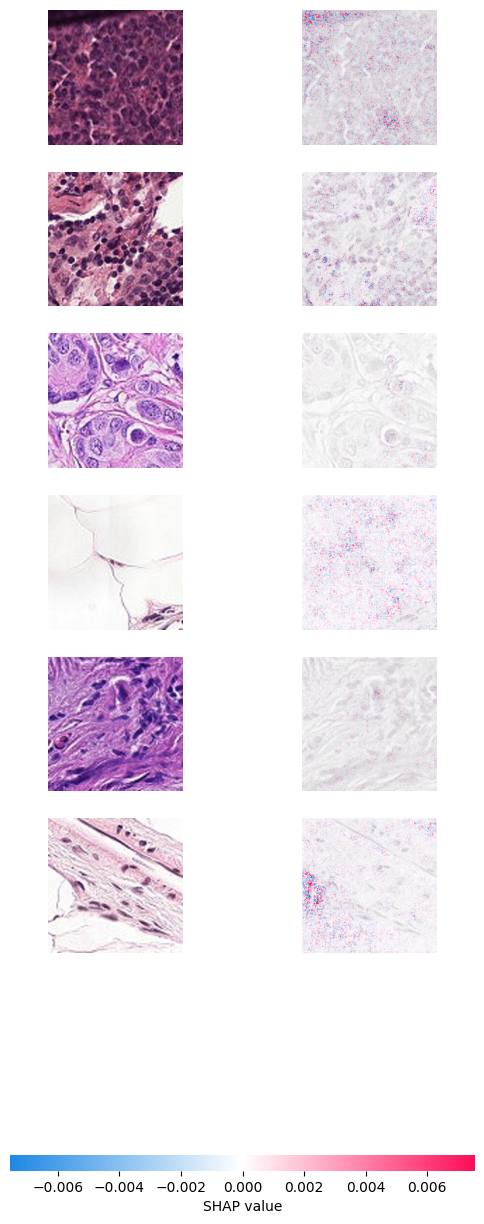

In [29]:
# ============================================================
# CELL 12 — SHAP Explainability using saved model + test_gen
# Works with custom HistopathSequence
# ============================================================

!pip install -q shap

import os
import numpy as np
import tensorflow as tf
import shap
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load saved best model
# ------------------------------------------------------------
MODEL_PATH = "/kaggle/working/outputs/best_efficientnet_smote_model.keras"

best_model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("✅ Best model loaded successfully")
print("Model path:", MODEL_PATH)

# ------------------------------------------------------------
# 2. Collect images from custom test generator
# ------------------------------------------------------------
def collect_images_from_sequence(generator, total_images):
    images = []
    labels = []

    for batch_idx in range(len(generator)):
        batch = generator[batch_idx]

        # Handles (x, y) or (x, y, something_extra)
        batch_x = batch[0]
        batch_y = batch[1] if len(batch) > 1 else None

        for i in range(len(batch_x)):
            images.append(batch_x[i])

            if batch_y is not None:
                labels.append(batch_y[i])

            if len(images) >= total_images:
                break

        if len(images) >= total_images:
            break

    images = np.array(images)

    if len(labels) > 0:
        labels = np.array(labels)
    else:
        labels = None

    return images, labels


BACKGROUND_SIZE = 20      # images used as SHAP background
SHAP_SAMPLE_SIZE = 6      # test images to explain

total_needed = BACKGROUND_SIZE + SHAP_SAMPLE_SIZE

x_all, y_all = collect_images_from_sequence(test_gen, total_needed)

background_images = x_all[:BACKGROUND_SIZE]
test_images = x_all[BACKGROUND_SIZE:BACKGROUND_SIZE + SHAP_SAMPLE_SIZE]

if y_all is not None:
    test_labels = y_all[BACKGROUND_SIZE:BACKGROUND_SIZE + SHAP_SAMPLE_SIZE]
else:
    test_labels = None

print("✅ Background images shape:", background_images.shape)
print("✅ Test sample images shape:", test_images.shape)

# ------------------------------------------------------------
# 3. Class names
# ------------------------------------------------------------
if hasattr(test_gen, "class_indices"):
    class_names = list(test_gen.class_indices.keys())
elif hasattr(test_gen, "classes"):
    unique_classes = sorted(list(set(test_gen.classes)))
    class_names = [str(c) for c in unique_classes]
else:
    output_units = best_model.output_shape[-1]
    if output_units == 1:
        class_names = ["Class 0", "Class 1"]
    else:
        class_names = [f"Class {i}" for i in range(output_units)]

print("Class names:", class_names)

# ------------------------------------------------------------
# 4. Predictions on selected test images
# ------------------------------------------------------------
preds = best_model.predict(test_images)

if preds.shape[-1] == 1:
    # Binary sigmoid output
    predicted_classes = (preds.ravel() >= 0.5).astype(int)
    predicted_scores = preds.ravel()
else:
    # Multi-class softmax output
    predicted_classes = np.argmax(preds, axis=1)
    predicted_scores = np.max(preds, axis=1)

print("\n✅ Predictions:")
for i, cls in enumerate(predicted_classes):
    cls_name = class_names[cls] if cls < len(class_names) else f"Class {cls}"
    print(f"Image {i+1}: Predicted = {cls_name}, Score = {predicted_scores[i]:.4f}")

# ------------------------------------------------------------
# 5. Normalize images only for display
# ------------------------------------------------------------
def normalize_for_display(x):
    x = np.array(x)

    if x.min() >= 0 and x.max() <= 1:
        return x

    if x.min() >= 0 and x.max() <= 255:
        return x / 255.0

    return (x - x.min()) / (x.max() - x.min() + 1e-8)

display_images = normalize_for_display(test_images)

# ------------------------------------------------------------
# 6. SHAP Gradient Explainer
# ------------------------------------------------------------
print("\nCalculating SHAP values...")

explainer = shap.GradientExplainer(best_model, background_images)
shap_values = explainer.shap_values(test_images)

print("✅ SHAP values calculated")

# ------------------------------------------------------------
# 7. Prepare SHAP output safely
# ------------------------------------------------------------
if isinstance(shap_values, list):
    # Older SHAP format
    if len(shap_values) == 1:
        shap_to_plot = shap_values[0]
        print("Using single-output SHAP values")
    else:
        CLASS_TO_EXPLAIN = int(predicted_classes[0])
        shap_to_plot = shap_values[CLASS_TO_EXPLAIN]
        print("Explaining class:", CLASS_TO_EXPLAIN)

else:
    shap_values = np.array(shap_values)

    # Newer SHAP format can be:
    # samples, height, width, channels, classes
    if shap_values.ndim == 5:
        CLASS_TO_EXPLAIN = int(predicted_classes[0])
        shap_to_plot = shap_values[..., CLASS_TO_EXPLAIN]
        print("Explaining class:", CLASS_TO_EXPLAIN)
    else:
        shap_to_plot = shap_values
        print("Using SHAP values directly")

print("SHAP plot shape:", np.array(shap_to_plot).shape)
print("Image plot shape:", display_images.shape)

# ------------------------------------------------------------
# 8. Plot SHAP explanations
# ------------------------------------------------------------
print("\nShowing SHAP explanations...")
print("Red areas increase the prediction.")
print("Blue areas decrease the prediction.")

shap.image_plot(
    shap_to_plot,
    display_images,
    show=True
)

✅ Best model loaded successfully
Model path: /kaggle/working/outputs/best_efficientnet_smote_model.keras
✅ Test images shape: (4, 200, 200, 3)
Class names: ['Class 0', 'Class 1']

Image 1
Predicted class: Class 0
Confidence: 0.9998


  0%|          | 0/1000 [00:00<?, ?it/s]

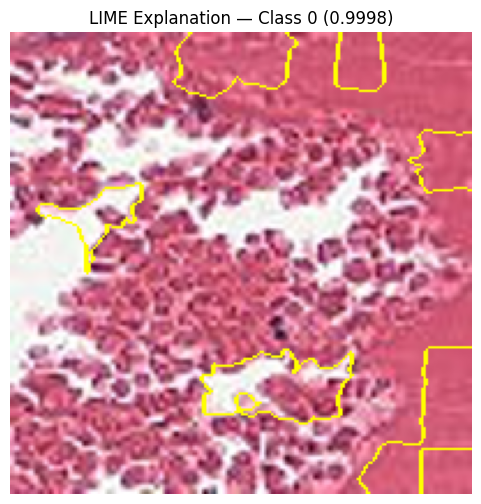


Image 2
Predicted class: Class 0
Confidence: 0.9982


  0%|          | 0/1000 [00:00<?, ?it/s]

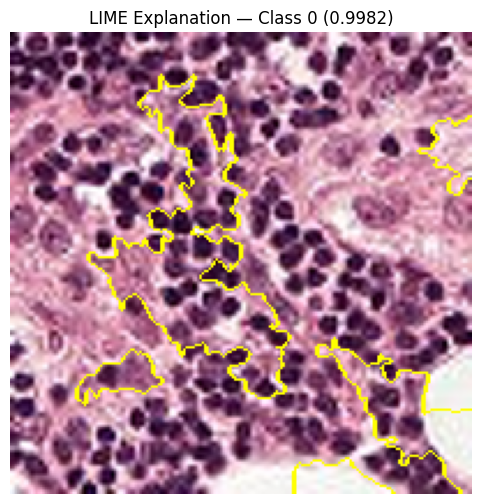


Image 3
Predicted class: Class 0
Confidence: 0.9964


  0%|          | 0/1000 [00:00<?, ?it/s]

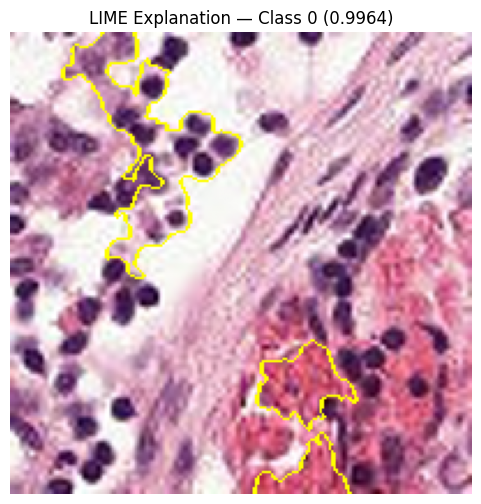


Image 4
Predicted class: Class 0
Confidence: 0.9995


  0%|          | 0/1000 [00:00<?, ?it/s]

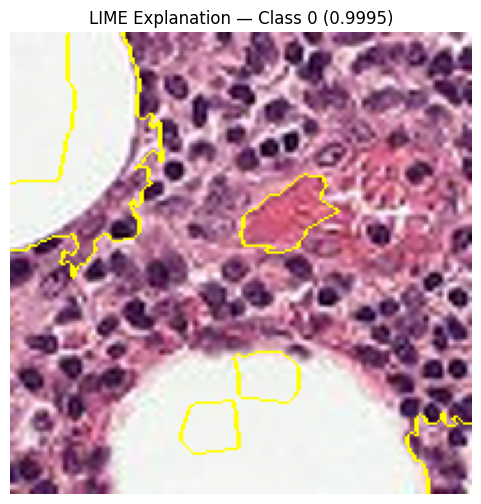

In [30]:
# ============================================================
# CELL 13 — LIME Explainability using saved model + test_gen
# Works with custom HistopathSequence
# ============================================================

!pip install -q lime scikit-image

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from lime import lime_image
from skimage.segmentation import mark_boundaries, slic

# ------------------------------------------------------------
# 1. Load saved best model
# ------------------------------------------------------------
MODEL_PATH = "/kaggle/working/outputs/best_efficientnet_smote_model.keras"

best_model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("✅ Best model loaded successfully")
print("Model path:", MODEL_PATH)

# ------------------------------------------------------------
# 2. Collect images from custom test generator
# ------------------------------------------------------------
def collect_images_from_sequence(generator, total_images):
    images = []
    labels = []

    for batch_idx in range(len(generator)):
        batch = generator[batch_idx]

        batch_x = batch[0]
        batch_y = batch[1] if len(batch) > 1 else None

        for i in range(len(batch_x)):
            images.append(batch_x[i])

            if batch_y is not None:
                labels.append(batch_y[i])

            if len(images) >= total_images:
                break

        if len(images) >= total_images:
            break

    images = np.array(images)

    if len(labels) > 0:
        labels = np.array(labels)
    else:
        labels = None

    return images, labels


LIME_SAMPLE_SIZE = 4

test_images, test_labels = collect_images_from_sequence(test_gen, LIME_SAMPLE_SIZE)

print("✅ Test images shape:", test_images.shape)

# ------------------------------------------------------------
# 3. Class names
# ------------------------------------------------------------
if hasattr(test_gen, "class_indices"):
    class_names = list(test_gen.class_indices.keys())
else:
    output_units = best_model.output_shape[-1]
    if output_units == 1:
        class_names = ["Class 0", "Class 1"]
    else:
        class_names = [f"Class {i}" for i in range(output_units)]

print("Class names:", class_names)

# ------------------------------------------------------------
# 4. Prediction function for LIME
# ------------------------------------------------------------
def lime_predict_fn(images):
    """
    LIME sends perturbed images here.
    This function must return class probabilities.
    """

    images = np.array(images).astype(np.float32)

    preds = best_model.predict(images, verbose=0)

    # Binary sigmoid model: convert [p] into [1-p, p]
    if preds.shape[-1] == 1:
        p = preds.ravel()
        preds = np.column_stack([1 - p, p])

    return preds

# ------------------------------------------------------------
# 5. Helper function for display only
# ------------------------------------------------------------
def normalize_for_display(x):
    x = np.array(x)

    if x.min() >= 0 and x.max() <= 1:
        return x

    if x.min() >= 0 and x.max() <= 255:
        return x / 255.0

    return (x - x.min()) / (x.max() - x.min() + 1e-8)


display_images = normalize_for_display(test_images)

# ------------------------------------------------------------
# 6. Create LIME explainer
# ------------------------------------------------------------
explainer = lime_image.LimeImageExplainer(random_state=42)

# Segmentation function
def segmentation_fn(image):
    return slic(
        image,
        n_segments=100,
        compactness=10,
        sigma=1,
        start_label=1
    )

# ------------------------------------------------------------
# 7. Run LIME on selected test images
# ------------------------------------------------------------
NUM_SAMPLES = 1000      # reduce to 500 if slow
NUM_FEATURES = 10       # number of important regions to show

for idx in range(len(test_images)):

    image_for_model = test_images[idx]
    image_for_display = display_images[idx]

    preds = lime_predict_fn(np.expand_dims(image_for_model, axis=0))
    predicted_class = int(np.argmax(preds[0]))
    confidence = float(np.max(preds[0]))

    predicted_name = (
        class_names[predicted_class]
        if predicted_class < len(class_names)
        else f"Class {predicted_class}"
    )

    print("\n" + "=" * 60)
    print(f"Image {idx + 1}")
    print(f"Predicted class: {predicted_name}")
    print(f"Confidence: {confidence:.4f}")

    explanation = explainer.explain_instance(
        image=image_for_model.astype(np.double),
        classifier_fn=lime_predict_fn,
        top_labels=2,
        hide_color=0,
        num_samples=NUM_SAMPLES,
        segmentation_fn=segmentation_fn
    )

    temp, mask = explanation.get_image_and_mask(
        label=predicted_class,
        positive_only=True,
        negative_only=False,
        hide_rest=False,
        num_features=NUM_FEATURES
    )

    # Normalize temp for better display
    temp_display = normalize_for_display(temp)

    plt.figure(figsize=(6, 6))
    plt.imshow(mark_boundaries(temp_display, mask))
    plt.title(f"LIME Explanation — {predicted_name} ({confidence:.4f})")
    plt.axis("off")
    plt.show()

In [31]:
# ============================================================
# CELL 14 — Research Paper Essential Plots
# Works with saved .keras model + custom HistopathSequence test_gen
# ============================================================

import os
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import FileLink, display
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------
MODEL_PATH = "/kaggle/working/outputs/best_efficientnet_smote_model.keras"

PLOT_DIR = "/kaggle/working/research_paper_plots"
os.makedirs(PLOT_DIR, exist_ok=True)

ZIP_PATH = "/kaggle/working/research_paper_plots.zip"

# Possible training history locations
HISTORY_CANDIDATES = [
    "/kaggle/working/outputs/training_history.csv",
    "/kaggle/working/training_history.csv"
]

# ------------------------------------------------------------
# 2. Load model
# ------------------------------------------------------------
best_model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("✅ Model loaded successfully")
print("Model path:", MODEL_PATH)

# ------------------------------------------------------------
# 3. Class names
# ------------------------------------------------------------
def get_class_names(generator, model):
    if hasattr(generator, "class_indices"):
        class_indices = generator.class_indices
        return [name for name, idx in sorted(class_indices.items(), key=lambda x: x[1])]

    output_units = model.output_shape[-1]

    if output_units == 1:
        return ["Class 0", "Class 1"]
    else:
        return [f"Class {i}" for i in range(output_units)]

class_names = get_class_names(test_gen, best_model)
num_classes = len(class_names)

print("Class names:", class_names)

# ------------------------------------------------------------
# 4. Helper functions
# ------------------------------------------------------------
def labels_to_indices(y):
    y = np.array(y)

    if y.ndim == 2 and y.shape[1] > 1:
        return np.argmax(y, axis=1)

    return y.reshape(-1).astype(int)


def normalize_for_display(x):
    x = np.array(x)

    if x.min() >= 0 and x.max() <= 1:
        return x

    if x.min() >= 0 and x.max() <= 255:
        return x / 255.0

    return (x - x.min()) / (x.max() - x.min() + 1e-8)


def save_current_plot(filename):
    png_path = os.path.join(PLOT_DIR, filename + ".png")
    pdf_path = os.path.join(PLOT_DIR, filename + ".pdf")

    plt.tight_layout()
    plt.savefig(png_path, dpi=300, bbox_inches="tight")
    plt.savefig(pdf_path, bbox_inches="tight")
    plt.show()

    print("Saved:", png_path)
    print("Saved:", pdf_path)


def prediction_to_probabilities(preds):
    preds = np.array(preds)

    # Binary sigmoid model: shape = (n, 1)
    if preds.ndim == 2 and preds.shape[1] == 1:
        p = preds.ravel()

        # If logits, convert to probability
        if p.min() < 0 or p.max() > 1:
            p = 1 / (1 + np.exp(-p))

        return np.column_stack([1 - p, p])

    # Multiclass model: shape = (n, classes)
    if preds.ndim == 2:
        row_sums = preds.sum(axis=1)

        # If not probabilities, apply softmax
        if preds.min() < 0 or not np.allclose(row_sums, 1, atol=1e-2):
            preds = tf.nn.softmax(preds, axis=1).numpy()

        return preds

    raise ValueError("Unsupported prediction shape: " + str(preds.shape))


# ------------------------------------------------------------
# 5. Predict on full test set without using reset()
# ------------------------------------------------------------
y_true_list = []
y_prob_list = []

sample_images = []
sample_true = []
MAX_SAMPLE_IMAGES = 12

print("\nRunning predictions on test set...")

for batch_idx in range(len(test_gen)):
    batch = test_gen[batch_idx]

    batch_x = batch[0]
    batch_y = batch[1]

    batch_true = labels_to_indices(batch_y)

    batch_preds = best_model.predict(batch_x, verbose=0)
    batch_probs = prediction_to_probabilities(batch_preds)

    y_true_list.extend(batch_true)
    y_prob_list.extend(batch_probs)

    # Keep some images for sample prediction figure
    for i in range(len(batch_x)):
        if len(sample_images) < MAX_SAMPLE_IMAGES:
            sample_images.append(batch_x[i])
            sample_true.append(batch_true[i])

print("✅ Predictions completed")

y_true = np.array(y_true_list).astype(int)
y_prob = np.array(y_prob_list)

# If binary model but class_names missing second class
if y_prob.shape[1] == 2 and len(class_names) < 2:
    class_names = ["Class 0", "Class 1"]

num_classes = y_prob.shape[1]
y_pred = np.argmax(y_prob, axis=1)

print("Total test samples:", len(y_true))
print("Prediction probability shape:", y_prob.shape)

# ------------------------------------------------------------
# 6. Training history plots
# ------------------------------------------------------------
history_path = None

for candidate in HISTORY_CANDIDATES:
    if os.path.exists(candidate):
        history_path = candidate
        break

if history_path is not None:
    history_df = pd.read_csv(history_path)
    print("\n✅ Training history found:", history_path)
    print("History columns:", list(history_df.columns))

    # Loss curve
    if "loss" in history_df.columns:
        plt.figure(figsize=(7, 5))
        plt.plot(history_df["loss"], label="Training loss")

        if "val_loss" in history_df.columns:
            plt.plot(history_df["val_loss"], label="Validation loss")

        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training and Validation Loss")
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_current_plot("01_training_validation_loss")

    # Accuracy curve
    accuracy_cols = ["accuracy", "binary_accuracy", "categorical_accuracy", "sparse_categorical_accuracy"]

    train_acc_col = None
    val_acc_col = None

    for col in accuracy_cols:
        if col in history_df.columns:
            train_acc_col = col
            val_candidate = "val_" + col
            if val_candidate in history_df.columns:
                val_acc_col = val_candidate
            break

    if train_acc_col is not None:
        plt.figure(figsize=(7, 5))
        plt.plot(history_df[train_acc_col], label="Training accuracy")

        if val_acc_col is not None:
            plt.plot(history_df[val_acc_col], label="Validation accuracy")

        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title("Training and Validation Accuracy")
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_current_plot("02_training_validation_accuracy")

    # AUC curve
    auc_cols = ["auc", "AUC"]

    train_auc_col = None
    val_auc_col = None

    for col in auc_cols:
        if col in history_df.columns:
            train_auc_col = col
            val_candidate = "val_" + col
            if val_candidate in history_df.columns:
                val_auc_col = val_candidate
            break

    if train_auc_col is not None:
        plt.figure(figsize=(7, 5))
        plt.plot(history_df[train_auc_col], label="Training AUC")

        if val_auc_col is not None:
            plt.plot(history_df[val_auc_col], label="Validation AUC")

        plt.xlabel("Epoch")
        plt.ylabel("AUC")
        plt.title("Training and Validation AUC")
        plt.legend()
        plt.grid(True, alpha=0.3)
        save_current_plot("03_training_validation_auc")

else:
    print("\n⚠️ Training history CSV not found. Skipping training curve plots.")

# ------------------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------------------
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

plt.figure(figsize=(7, 6))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(num_classes), class_names[:num_classes], rotation=45, ha="right")
plt.yticks(range(num_classes), class_names[:num_classes])
plt.colorbar()

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center")

save_current_plot("04_confusion_matrix")

# Normalized confusion matrix
cm_norm = cm.astype("float") / np.maximum(cm.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(7, 6))
plt.imshow(cm_norm)
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(num_classes), class_names[:num_classes], rotation=45, ha="right")
plt.yticks(range(num_classes), class_names[:num_classes])
plt.colorbar()

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center")

save_current_plot("05_normalized_confusion_matrix")

# ------------------------------------------------------------
# 8. ROC curve
# ------------------------------------------------------------
plt.figure(figsize=(7, 6))

roc_auc_scores = {}

if num_classes == 2:
    fpr, tpr, _ = roc_curve(y_true, y_prob[:, 1])
    roc_auc = auc(fpr, tpr)
    roc_auc_scores[class_names[1]] = roc_auc

    plt.plot(fpr, tpr, label=f"{class_names[1]} AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

else:
    y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))

    for class_idx in range(num_classes):
        if len(np.unique(y_true_bin[:, class_idx])) < 2:
            continue

        fpr, tpr, _ = roc_curve(y_true_bin[:, class_idx], y_prob[:, class_idx])
        roc_auc = auc(fpr, tpr)
        roc_auc_scores[class_names[class_idx]] = roc_auc

        plt.plot(fpr, tpr, label=f"{class_names[class_idx]} AUC = {roc_auc:.4f}")

    plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
save_current_plot("06_roc_curve")

# ------------------------------------------------------------
# 9. Precision-Recall curve
# ------------------------------------------------------------
plt.figure(figsize=(7, 6))

average_precision_scores = {}

if num_classes == 2:
    precision, recall, _ = precision_recall_curve(y_true, y_prob[:, 1])
    ap = average_precision_score(y_true, y_prob[:, 1])
    average_precision_scores[class_names[1]] = ap

    plt.plot(recall, precision, label=f"{class_names[1]} AP = {ap:.4f}")

else:
    y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))

    for class_idx in range(num_classes):
        if len(np.unique(y_true_bin[:, class_idx])) < 2:
            continue

        precision, recall, _ = precision_recall_curve(
            y_true_bin[:, class_idx],
            y_prob[:, class_idx]
        )

        ap = average_precision_score(y_true_bin[:, class_idx], y_prob[:, class_idx])
        average_precision_scores[class_names[class_idx]] = ap

        plt.plot(recall, precision, label=f"{class_names[class_idx]} AP = {ap:.4f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
save_current_plot("07_precision_recall_curve")

# ------------------------------------------------------------
# 10. Classification report CSV + metrics bar plot
# ------------------------------------------------------------
report_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names[:num_classes],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()
report_csv_path = os.path.join(PLOT_DIR, "classification_report.csv")
report_df.to_csv(report_csv_path)

print("Saved:", report_csv_path)
display(report_df)

# Per-class precision, recall, F1-score bar plot
per_class_df = report_df.iloc[:num_classes][["precision", "recall", "f1-score"]]

x = np.arange(num_classes)
width = 0.25

plt.figure(figsize=(9, 6))
plt.bar(x - width, per_class_df["precision"], width, label="Precision")
plt.bar(x, per_class_df["recall"], width, label="Recall")
plt.bar(x + width, per_class_df["f1-score"], width, label="F1-score")

plt.xlabel("Class")
plt.ylabel("Score")
plt.title("Per-Class Classification Metrics")
plt.xticks(x, class_names[:num_classes], rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
save_current_plot("08_per_class_metrics")

# ------------------------------------------------------------
# 11. Sample prediction grid
# ------------------------------------------------------------
sample_images = np.array(sample_images)
sample_true = np.array(sample_true)

sample_probs = y_prob[:len(sample_images)]
sample_preds = np.argmax(sample_probs, axis=1)
sample_conf = np.max(sample_probs, axis=1)

display_sample_images = normalize_for_display(sample_images)

cols = 4
rows = int(np.ceil(len(display_sample_images) / cols))

plt.figure(figsize=(16, 4 * rows))

for i in range(len(display_sample_images)):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(display_sample_images[i])
    plt.axis("off")

    true_name = class_names[sample_true[i]] if sample_true[i] < len(class_names) else str(sample_true[i])
    pred_name = class_names[sample_preds[i]] if sample_preds[i] < len(class_names) else str(sample_preds[i])

    title = f"True: {true_name}\nPred: {pred_name}\nConf: {sample_conf[i]:.3f}"
    plt.title(title, fontsize=10)

save_current_plot("09_sample_predictions")

# ------------------------------------------------------------
# 12. Save summary metrics
# ------------------------------------------------------------
summary_path = os.path.join(PLOT_DIR, "summary_metrics.txt")

with open(summary_path, "w") as f:
    f.write("Research Paper Model Evaluation Summary\n")
    f.write("=" * 45 + "\n\n")

    f.write(f"Model path: {MODEL_PATH}\n")
    f.write(f"Total test samples: {len(y_true)}\n")
    f.write(f"Classes: {class_names[:num_classes]}\n\n")

    f.write("Classification Report:\n")
    f.write(classification_report(
        y_true,
        y_pred,
        target_names=class_names[:num_classes],
        zero_division=0
    ))

    f.write("\n\nROC AUC Scores:\n")
    for k, v in roc_auc_scores.items():
        f.write(f"\n{k}: {v:.4f}")

    f.write("\n\nAverage Precision Scores:\n")
    for k, v in average_precision_scores.items():
        f.write(f"\n{k}: {v:.4f}")

print("Saved:", summary_path)

# ------------------------------------------------------------
# 13. ZIP all plots for download
# ------------------------------------------------------------
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

shutil.make_archive(
    base_name=ZIP_PATH.replace(".zip", ""),
    format="zip",
    root_dir=PLOT_DIR
)

print("\n✅ All research paper plots created successfully.")
print("Plots folder:", PLOT_DIR)
print("ZIP file:", ZIP_PATH)

display(FileLink(ZIP_PATH, result_html_prefix="Download all research paper plots: "))

✅ Model loaded successfully
Model path: /kaggle/working/outputs/best_efficientnet_smote_model.keras
Class names: ['Class 0', 'Class 1']

Running predictions on test set...


KeyboardInterrupt: 

In [24]:
if os.path.exists(OFFICIAL_TEST_DIR):
    official_files = sorted([f for f in os.listdir(OFFICIAL_TEST_DIR) if f.endswith(".tif")])

    if len(official_files) > 0:
        official_test_df = pd.DataFrame({
            "id": [Path(f).stem for f in official_files],
            "filepath": [os.path.join(OFFICIAL_TEST_DIR, f) for f in official_files],
            "label": 0
        })

        official_test_gen = HistopathSequence(
            official_test_df,
            batch_size=BATCH_SIZE,
            shuffle=False,
            use_smote=False
        )

        official_probs = model.predict(official_test_gen, verbose=1).ravel()

        submission = pd.DataFrame({
            "id": official_test_df["id"].values,
            "label": official_probs
        })

        submission_path = os.path.join(OUTPUT_DIR, "submission.csv")
        submission.to_csv(submission_path, index=False)
        print("Saved:", submission_path)
        print(submission.head())
    else:
        print("Official test folder is empty.")
else:
    print("Official test folder not found.")


  39/1796 ━━━━━━━━━━━━━━━━━━━━ 9:34 327ms/step

KeyboardInterrupt: 

In [25]:
# ============================================================
# CELL 19 — Final output files check
# ============================================================

print("Saved files in OUTPUT_DIR:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print("-", f)


Saved files in OUTPUT_DIR:
- .virtual_documents
- best_model_download.zip
- gradcam_examples.png
- integrated_gradients_examples.png
- outputs
